In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST('./data', train=False, download=True, transform=transform)

batch_size = 2
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of test batches: {len(test_loader)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 107kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.98MB/s]


Training dataset size: 60000
Test dataset size: 10000
Number of training batches: 30000
Number of test batches: 5000


In [ ]:
class FCNN(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, num_classes):
        super(FCNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return F.log_softmax(x, dim=1)

print("FCNN model class defined.")

FCNN model class defined.


In [ ]:
learning_rate = 0.001
num_epochs = 5

print(f"Learning rate: {learning_rate}")
print(f"Number of epochs: {num_epochs}")

Learning rate: 0.001
Number of epochs: 5


In [ ]:
input_size = 28 * 28 # MNIST images are 28x28
hidden_size1 = 128
hidden_size2 = 64
num_classes = 10

model = FCNN(input_size, hidden_size1, hidden_size2, num_classes)

# Re-initialize optimizer with the actual model parameters
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print(f"Model instantiated: {model.__class__.__name__}")
print(f"Optimizer re-initialized with model parameters: {optimizer.__class__.__name__}")

def train(model, train_loader, criterion, optimizer, epoch):
    model.train() # Set the model to training mode
    for batch_idx, (data, target) in enumerate(train_loader):
        # Flatten the input data
        data = data.view(data.size(0), -1)

        # Forward pass
        output = model(data)
        loss = criterion(output, target)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            print(f'Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100. * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}')

print("Training function `train` defined.")

Model instantiated: FCNN
Optimizer re-initialized with model parameters: Adam
Training function `train` defined.


In [ ]:
def test(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0
    correct = 0
    with torch.no_grad(): # Disable gradient calculations
        for data, target in test_loader:
            # Flatten the input data
            data = data.view(data.size(0), -1)

            # Forward pass
            output = model(data)
            test_loss += criterion(output, target).item() # Sum up batch loss
            pred = output.argmax(dim=1, keepdim=True) # Get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset) # Average loss per sample

    print(f'\nTest set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(test_loader.dataset)} ({100. * correct / len(test_loader.dataset):.0f}%)\n')
    return test_loss, correct

print("Evaluation function `test` redefined to return loss and correct predictions.")

Evaluation function `test` redefined to return loss and correct predictions.


In [ ]:
criterion = nn.CrossEntropyLoss()

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(1, num_epochs + 1):
    train(model, train_loader, criterion, optimizer, epoch)
    test_loss, correct = test(model, test_loader, criterion)

    test_losses.append(test_loss)
    test_accuracies.append(100. * correct / len(test_loader.dataset))

print("Training and evaluation loop completed.")
print(f"Final Test Loss: {test_losses[-1]:.4f}")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.305525
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.359626
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.284369
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.254329
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.232376
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.093540
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.177479
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.145025
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.158921
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.090689

Test set: Average loss: 0.0021, Accuracy: 9602/10000 (96%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.054890
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.148628
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.055697
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.121172
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.082170
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.096750
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.211260
Train Epoch: 2 [44800/60000 (75%)]	Loss: 0.053606
Train Epoch: 2 [51200/60000 (85%)]	Loss: 0.080694
T

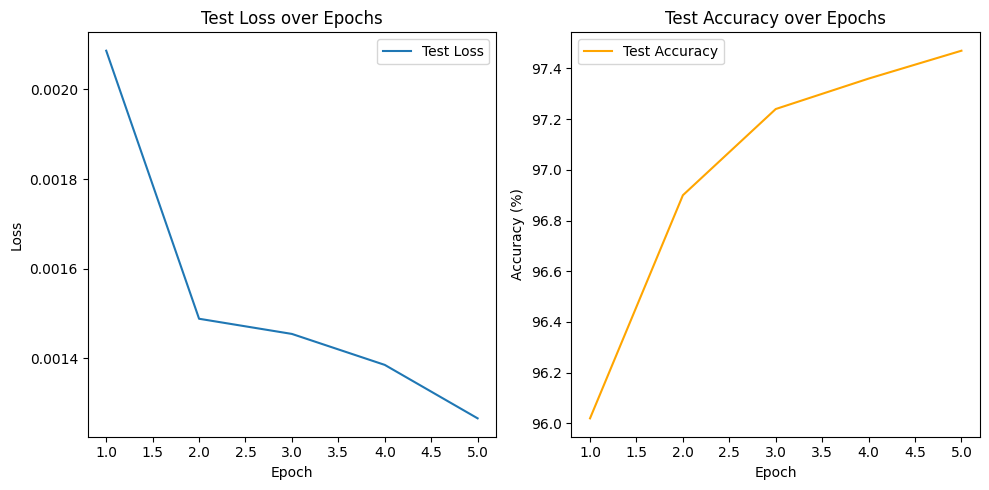

Plots generated for test loss and accuracy.


In [ ]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(10, 5))

# Plot Test Loss
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.plot(epochs, test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Test Loss over Epochs')
plt.legend()

# Plot Test Accuracy
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.plot(epochs, test_accuracies, label='Test Accuracy', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Test Accuracy over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

print("Plots generated for test loss and accuracy.")